# 1. Installs Python libraries for data analysis, visualization, and machine learning.

In [3]:
%pip install pandas numpy scikit-learn matplotlib seaborn



[notice] A new release of pip is available: 25.2 -> 26.0.1
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


# 2. Data Cleaning
## 2.1. Loads the clinical dataset, checks its dimensions, and displays the first rows.


In [4]:
import pandas as pd
import numpy as np

# 1. Load the dataset from the local file
# We specify header=None because the file doesn't have column names at the top
df = pd.read_csv('MI.data', header=None, na_values='?')

# 2. Check the dimensions of the data
print(f"Dataset Shape: {df.shape[0]} rows and {df.shape[1]} columns")

# 3. Display the first 5 rows to verify it loaded correctly
display(df.head())

Dataset Shape: 1700 rows and 124 columns


,0,1,2,3,4,5,6,7,8,9,...,114,115,116,117,118,119,120,121,122,123
0,1,77.0,1,2.0,1.0,1.0,2.0,NaN,3.0,0.0,...,0,0,0,0,0,0,0,0,0,0
1,2,55.0,1,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0,0,0,0,0,0,0,0,0,0
2,3,52.0,1,0.0,0.0,0.0,2.0,NaN,2.0,0.0,...,0,0,0,0,0,0,0,0,0,0
3,4,68.0,0,0.0,0.0,0.0,2.0,NaN,2.0,0.0,...,0,0,0,0,0,0,1,0,0,0
4,5,60.0,1,0.0,0.0,0.0,2.0,NaN,3.0,0.0,...,0,0,0,0,0,0,0,0,0,0


## 2.2 Creates the binary "Target" variable for complications and eliminates original columns to prevent data leakage.

In [5]:
# 1. Isolate the 12 complication columns (columns 112 to 123)
complication_columns = df.iloc[:, 112:124]

# 2. Create a new column 'Target': 1 if ANY complication exists (sum > 0), 0 if NONE
df['Target'] = (complication_columns.sum(axis=1, skipna=True) > 0).astype(int)

# 3. Drop the original 12 complication columns to prevent data leakage
# This ensures our model doesn't use the specific complications to predict the general one!
df_clean = df.drop(columns=range(112, 124))

print(f"New shape after creating target: {df_clean.shape[0]} rows, {df_clean.shape[1]} columns")

# 4. Check how balanced our problem is
print("\nDistribution of Target (0 = No Complications, 1 = Complications):")
print(df_clean['Target'].value_counts(normalize=True) * 100)

New shape after creating target: 1700 rows, 113 columns

Distribution of Target (0 = No Complications, 1 = Complications):
Target
1    61.0
0    39.0
Name: proportion, dtype: float64


/var/folders/zm/cb182h793bs3vxtfz7b6scgr0000gn/T/ipykernel_939/2227641763.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['Target'] = (complication_columns.sum(axis=1, skipna=True) > 0).astype(int)


## 2.3. Calculates and displays the percentage of missing values for each clinical feature.

In [6]:
# 1. Fix the fragmentation warning from earlier
df_clean = df_clean.copy()

# 2. Calculate the percentage of missing values for each column
missing_percentages = df_clean.isnull().sum() / len(df_clean) * 100

# 3. Filter to show ONLY columns that actually have missing data
missing_data = missing_percentages[missing_percentages > 0].sort_values(ascending=False)

print(f"Total features with missing values: {len(missing_data)} out of 112")
print("\nTop 15 columns with the highest % of missing data:")
print(missing_data.head(15))

Total features with missing values: 110 out of 112

Top 15 columns with the highest % of missing data:
88    99.764706
7     95.764706
35    63.294118
34    63.294118
96    40.352941
97    39.823529
95    38.647059
84    22.058824
85    22.058824
83    21.823529
82    21.705882
87    16.764706
86    16.705882
36    15.705882
37    15.705882
dtype: float64


## 2.4 Drops columns that exceed the 30% missing data threshold.

In [7]:
# 1. Define our scientific threshold (30%)
threshold = 30.0

# 2. Identify which columns cross this threshold
cols_to_drop = missing_percentages[missing_percentages > threshold].index

# 3. Drop those columns from our dataset
df_reduced = df_clean.drop(columns=cols_to_drop)

# 4. Print the results to document for the final report
print(f"We dropped {len(cols_to_drop)} columns because they had > 30% missing data.")
print(f"Columns dropped: {list(cols_to_drop)}")
print(f"New dataset shape: {df_reduced.shape[0]} rows, {df_reduced.shape[1]} columns (including Target)")

We dropped 7 columns because they had > 30% missing data.
Columns dropped: [7, 34, 35, 88, 95, 96, 97]
New dataset shape: 1700 rows, 106 columns (including Target)


## 2.5. Separates features from the target and fills remaining missing values using median imputation.

In [8]:
from sklearn.impute import SimpleImputer

# 1. Separate the input features (X) from the output target (y)
X = df_reduced.drop(columns=['Target'])
y = df_reduced['Target']

# 2. Initialize the Imputer
# We use 'median' because it is scientifically robust for clinical variables
imputer = SimpleImputer(strategy='median')

# 3. Apply the imputer to fill in all missing values
# We wrap it back in a pd.DataFrame to keep our column names intact
X_imputed = pd.DataFrame(imputer.fit_transform(X), columns=X.columns)

# 4. Verify the results
missing_after = X_imputed.isnull().sum().sum()
print(f"Total missing values after imputation: {missing_after}")
print(f"Final Features (X) Shape: {X_imputed.shape}")
print(f"Target (y) Shape: {y.shape}")

Total missing values after imputation: 0
Final Features (X) Shape: (1700, 105)
Target (y) Shape: (1700,)


#  3. Training and perform Grid search to models
## 3.1 Logistic Regression model
### 3.1.1 Splits and scales the data, then trains and evaluates a baseline Logistic Regression model.

In [9]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, accuracy_score

# 1. Split the data (80% for training, 20% for testing)
# stratify=y ensures both sets maintain our 61% / 39% class balance
X_train, X_test, y_train, y_test = train_test_split(
    X_imputed, y, test_size=0.20, random_state=42, stratify=y
)

# 2. Scale the features (Standardization)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 3. Initialize and train the Logistic Regression model
# max_iter=1000 ensures the algorithm has enough time to learn across all 105 features
baseline_model = LogisticRegression(max_iter=1000, random_state=42)
baseline_model.fit(X_train_scaled, y_train)

# 4. Make predictions on the unseen Test set
y_pred = baseline_model.predict(X_test_scaled)

# 5. Print the Evaluation Metrics
print(f"Baseline Accuracy: {accuracy_score(y_test, y_pred) * 100:.2f}%\n")
print("Classification Report:")
print(classification_report(y_test, y_pred))

Baseline Accuracy: 78.53%

Classification Report:
              precision    recall  f1-score   support

           0       0.71      0.75      0.73       133
           1       0.83      0.81      0.82       207

    accuracy                           0.79       340
   macro avg       0.77      0.78      0.78       340
weighted avg       0.79      0.79      0.79       340



### 3.1.2 Performs a Grid Search with cross-validation to optimize the Logistic Regression hyperparameters.

In [10]:
from sklearn.model_selection import GridSearchCV

# 1. Define the hyperparameter grid
# We separate the dictionaries to ensure solver/penalty compatibility
param_grid = [
    {'solver': ['lbfgs'], 'penalty': ['l2', None], 'C': [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]},
    {'solver': ['liblinear'], 'penalty': ['l1', 'l2'], 'C': [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]}
]

# 2. Initialize GridSearchCV
# cv=5 uses 5-fold cross-validation
# scoring='f1' prioritizes the F1-score due to your slight class imbalance
# n_jobs=-1 uses all CPU cores to speed up the process
grid_search = GridSearchCV(
    estimator=LogisticRegression(max_iter=1000, random_state=42), 
    param_grid=param_grid, 
    scoring='f1', 
    cv=5, 
    n_jobs=-1,
    verbose=1 
)

# 3. Fit the Grid Search to the scaled training data
print("Running Grid Search...")
grid_search.fit(X_train_scaled, y_train)

# 4. Display the best parameters found during cross-validation
print(f"Best Parameters: {grid_search.best_params_}")
print(f"Best Cross-Validation F1-Score: {grid_search.best_score_:.4f}\n")

# 5. Evaluate the newly optimized model on your unseen test set
best_logreg = grid_search.best_estimator_
y_pred_opt = best_logreg.predict(X_test_scaled)

print("Optimized Classification Report:")
print(classification_report(y_test, y_pred_opt))

Running Grid Search...
Fitting 5 folds for each of 24 candidates, totalling 120 fits


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1

Best Parameters: {'C': 0.01, 'penalty': 'l2', 'solver': 'lbfgs'}
Best Cross-Validation F1-Score: 0.8182

Optimized Classification Report:
              precision    recall  f1-score   support

           0       0.69      0.71      0.70       133
           1       0.81      0.80      0.80       207

    accuracy                           0.76       340
   macro avg       0.75      0.75      0.75       340
weighted avg       0.76      0.76      0.76       340



/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


### 3.1.3 Runs a refined Grid Search to relax regularization and fix model underfitting.

In [11]:
from sklearn.model_selection import GridSearchCV

# 1. Define a narrower, higher-C parameter grid
# We omit 'penalty' to avoid FutureWarnings and rely on the default L2 regularization.
param_grid_refined = {
    'solver': ['lbfgs', 'liblinear'], 
    'C': [0.5, 1.0, 2.0, 5.0, 10.0, 25.0, 50.0]
}

# 2. Initialize the refined GridSearchCV
grid_search_refined = GridSearchCV(
    estimator=LogisticRegression(max_iter=1000, random_state=42), 
    param_grid=param_grid_refined, 
    scoring='f1', 
    cv=5, 
    n_jobs=-1,
    verbose=1 
)

# 3. Fit the new Grid Search
print("Running Refined Grid Search...")
grid_search_refined.fit(X_train_scaled, y_train)

# 4. Display the new best parameters
print(f"Best Parameters: {grid_search_refined.best_params_}")
print(f"Best Cross-Validation F1-Score: {grid_search_refined.best_score_:.4f}\n")

# 5. Evaluate the new model on the unseen test set
best_logreg_refined = grid_search_refined.best_estimator_
y_pred_refined = best_logreg_refined.predict(X_test_scaled)

print("Refined Classification Report:")
print(classification_report(y_test, y_pred_refined))

Running Refined Grid Search...
Fitting 5 folds for each of 14 candidates, totalling 70 fits
Best Parameters: {'C': 0.5, 'solver': 'lbfgs'}
Best Cross-Validation F1-Score: 0.8149

Refined Classification Report:
              precision    recall  f1-score   support

           0       0.72      0.75      0.74       133
           1       0.84      0.81      0.82       207

    accuracy                           0.79       340
   macro avg       0.78      0.78      0.78       340
weighted avg       0.79      0.79      0.79       340



## 3.2 Neural Network
### 3.2.1 Initializes, trains, and evaluates a baseline Neural Network (Multi-Layer Perceptron).

In [12]:
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import classification_report, accuracy_score

# 1. Initialize the Neural Network
# hidden_layer_sizes=(64, 32): Two hidden layers. The first has 64 neurons, the second has 32.
# activation='relu': The standard activation function that introduces non-linearity.
# solver='adam': A robust, efficient optimizer for training neural networks.
# early_stopping=True: This automatically sets aside a small validation set and stops training if the model starts to overfit.
mlp_model = MLPClassifier(
    hidden_layer_sizes=(64, 32), 
    activation='relu', 
    solver='adam', 
    max_iter=1000, 
    random_state=42,
    early_stopping=True 
)

# 2. Train the model on the scaled training data
print("Training the Neural Network...")
mlp_model.fit(X_train_scaled, y_train)

# 3. Make predictions on the unseen test set
y_pred_mlp = mlp_model.predict(X_test_scaled)

# 4. Print the Evaluation Metrics
print(f"Neural Network Accuracy: {accuracy_score(y_test, y_pred_mlp) * 100:.2f}%\n")
print("Neural Network Classification Report:")
print(classification_report(y_test, y_pred_mlp))

Training the Neural Network...
Neural Network Accuracy: 76.47%

Neural Network Classification Report:
              precision    recall  f1-score   support

           0       0.70      0.70      0.70       133
           1       0.81      0.81      0.81       207

    accuracy                           0.76       340
   macro avg       0.75      0.75      0.75       340
weighted avg       0.76      0.76      0.76       340



### 3.2.2 Optimizes the Neural Network's architecture and regularization to prevent overfitting.

In [13]:
from sklearn.model_selection import GridSearchCV
from sklearn.neural_network import MLPClassifier

# 1. Define the hyperparameter grid for the Neural Network
param_grid_mlp = {
    # Test a single hidden layer vs two hidden layers
    'hidden_layer_sizes': [(32,), (64,), (64, 32), (128, 64)],
    # alpha is the L2 penalty (regularization term). Higher values = stronger regularization
    'alpha': [0.0001, 0.001, 0.01, 0.1, 1.0],
    # Initial learning rate for the Adam optimizer
    'learning_rate_init': [0.001, 0.01]
}

# 2. Initialize the Grid Search
# We remove early_stopping here. Cross-validation (cv=5) already prevents overfitting 
# by testing on distinct folds, allowing us to utilize 100% of the training data.
grid_search_mlp = GridSearchCV(
    estimator=MLPClassifier(solver='adam', max_iter=1500, random_state=42), 
    param_grid=param_grid_mlp, 
    scoring='f1', 
    cv=5, 
    n_jobs=-1,
    verbose=1 
)

# 3. Fit the Grid Search to the scaled training data
print("Running Grid Search for Neural Network...")
grid_search_mlp.fit(X_train_scaled, y_train)

# 4. Display the best parameters
print(f"Best MLP Parameters: {grid_search_mlp.best_params_}")
print(f"Best MLP CV F1-Score: {grid_search_mlp.best_score_:.4f}\n")

# 5. Evaluate the optimized Neural Network on the unseen test set
best_mlp = grid_search_mlp.best_estimator_
y_pred_mlp_opt = best_mlp.predict(X_test_scaled)

print("Optimized Neural Network Classification Report:")
print(classification_report(y_test, y_pred_mlp_opt))

Running Grid Search for Neural Network...
Fitting 5 folds for each of 40 candidates, totalling 200 fits
Best MLP Parameters: {'alpha': 1.0, 'hidden_layer_sizes': (64,), 'learning_rate_init': 0.01}
Best MLP CV F1-Score: 0.8194

Optimized Neural Network Classification Report:
              precision    recall  f1-score   support

           0       0.71      0.78      0.74       133
           1       0.85      0.79      0.82       207

    accuracy                           0.79       340
   macro avg       0.78      0.79      0.78       340
weighted avg       0.79      0.79      0.79       340



## 3.3 Random Forest
### 3.3.1 Optimizes a Random Forest classifier to capture complex, non-linear interactions in the data.

In [14]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report

# 1. Define the hyperparameter grid for Random Forest
# - n_estimators: The number of decision trees in the forest.
# - max_depth: How deep each tree is allowed to grow. 'None' means they grow until pure.
# - min_samples_split: Minimum number of samples required to split an internal node.
# - min_samples_leaf: Minimum number of samples required to be at a leaf node.
param_grid_rf = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

# 2. Initialize the Grid Search
# Random Forests do not necessarily require scaled data, but using X_train_scaled 
# keeps our methodology consistent across all models.
grid_search_rf = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42), 
    param_grid=param_grid_rf, 
    scoring='f1', 
    cv=5, 
    n_jobs=-1,
    verbose=1 
)

# 3. Fit the Grid Search to the training data
print("Running Grid Search for Random Forest...")
grid_search_rf.fit(X_train_scaled, y_train)

# 4. Display the best parameters found
print(f"Best RF Parameters: {grid_search_rf.best_params_}")
print(f"Best RF CV F1-Score: {grid_search_rf.best_score_:.4f}\n")

# 5. Evaluate the optimized Random Forest on the unseen test set
best_rf = grid_search_rf.best_estimator_
y_pred_rf = best_rf.predict(X_test_scaled)

print("Optimized Random Forest Classification Report:")
print(classification_report(y_test, y_pred_rf))

Running Grid Search for Random Forest...
Fitting 5 folds for each of 81 candidates, totalling 405 fits
Best RF Parameters: {'max_depth': 20, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 300}
Best RF CV F1-Score: 0.8645

Optimized Random Forest Classification Report:
              precision    recall  f1-score   support

           0       0.76      0.80      0.78       133
           1       0.86      0.84      0.85       207

    accuracy                           0.82       340
   macro avg       0.81      0.82      0.81       340
weighted avg       0.82      0.82      0.82       340



# 4. Building model from scratch
## 4.1 Logistic Regresion 
### 4.1.1 Builds a custom Logistic Regression class from scratch using NumPy and gradient descent.

In [17]:
import numpy as np
from sklearn.metrics import classification_report, accuracy_score

class CustomLogisticRegression:
    def __init__(self, learning_rate=0.01, n_iterations=1000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.weights = None
        self.bias = None
        self.cost_history = [] # NEW: List to track the loss

    def _sigmoid(self, z):
        z = np.clip(z, -250, 250)
        return 1 / (1 + np.exp(-z))

    def _compute_cost(self, y_true, y_pred):
        # NEW: Mathematical formula for binary cross-entropy (log-loss)
        n_samples = len(y_true)
        # Add a tiny epsilon to prevent taking the log of 0
        epsilon = 1e-9 
        cost = -(1 / n_samples) * np.sum(y_true * np.log(y_pred + epsilon) + (1 - y_true) * np.log(1 - y_pred + epsilon))
        return cost

    def fit(self, X, y):
        n_samples, n_features = X.shape
        self.weights = np.zeros(n_features)
        self.bias = 0
        y_array = np.array(y)
        self.cost_history = [] # Reset history on new fit

        for i in range(self.n_iterations):
            linear_model = np.dot(X, self.weights) + self.bias
            y_predicted = self._sigmoid(linear_model)

            dw = (1 / n_samples) * np.dot(X.T, (y_predicted - y_array))
            db = (1 / n_samples) * np.sum(y_predicted - y_array)

            self.weights -= self.learning_rate * dw
            self.bias -= self.learning_rate * db
            
            # NEW: Calculate and save the cost every 100 iterations
            if i % 100 == 0:
                cost = self._compute_cost(y_array, y_predicted)
                self.cost_history.append(cost)

    def predict(self, X):
        linear_model = np.dot(X, self.weights) + self.bias
        y_predicted = self._sigmoid(linear_model)
        y_predicted_cls = [1 if i > 0.5 else 0 for i in y_predicted]
        return np.array(y_predicted_cls)

### 4.1.2 Trains and evaluates our custom-built Logistic Regression model on the test data.

In [18]:
# 1. Initialize our custom model
# We can start with a learning rate of 0.1 and 2000 iterations
custom_model = CustomLogisticRegression(learning_rate=0.1, n_iterations=2000)

# 2. Train the model using the scaled training data
print("Training Custom Logistic Regression...")
custom_model.fit(X_train_scaled, y_train)

# 3. Make predictions on the unseen test set
y_pred_custom = custom_model.predict(X_test_scaled)

# 4. Print the Evaluation Metrics
print(f"Custom Model Accuracy: {accuracy_score(y_test, y_pred_custom) * 100:.2f}%\n")
print("Custom Model Classification Report:")
print(classification_report(y_test, y_pred_custom))

Training Custom Logistic Regression...
Custom Model Accuracy: 78.82%

Custom Model Classification Report:
              precision    recall  f1-score   support

           0       0.72      0.75      0.74       133
           1       0.84      0.81      0.82       207

    accuracy                           0.79       340
   macro avg       0.78      0.78      0.78       340
weighted avg       0.79      0.79      0.79       340



### 4.1.3 Plots a learning curve to visualize the gradient descent algorithm minimizing the cost over time.

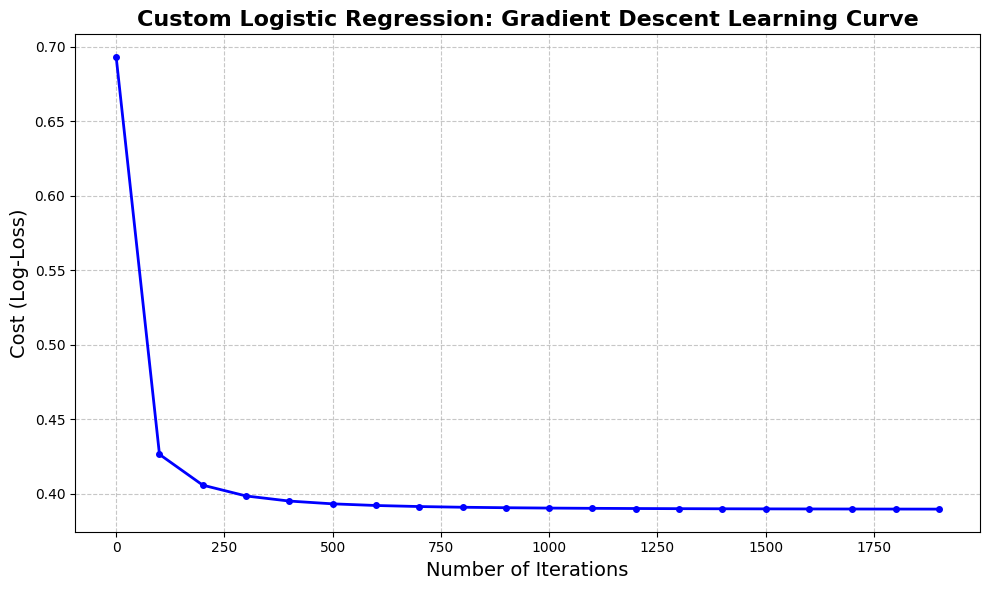

In [19]:
import matplotlib.pyplot as plt

# 1. Set up the figure size
plt.figure(figsize=(10, 6))

# 2. Generate the x-axis values
# Since we saved the cost every 100 iterations, we multiply by 100 to reflect the true iteration number
iterations = [i * 100 for i in range(len(custom_model.cost_history))]

# 3. Plot the cost history
plt.plot(iterations, custom_model.cost_history, color='blue', linewidth=2, marker='o', markersize=4)

# 4. Add titles and labels to make it presentation-ready
plt.title('Custom Logistic Regression: Gradient Descent Learning Curve', fontsize=16, fontweight='bold')
plt.xlabel('Number of Iterations', fontsize=14)
plt.ylabel('Cost (Log-Loss)', fontsize=14)

# 5. Add a grid for readability
plt.grid(True, linestyle='--', alpha=0.7)

# 6. Display the plot
plt.tight_layout()
plt.show()

# 5. Visualization

## 5.1 Plots a bar chart with error bars representing the standard deviation across 5-fold cross-validation to demonstrate model stability.

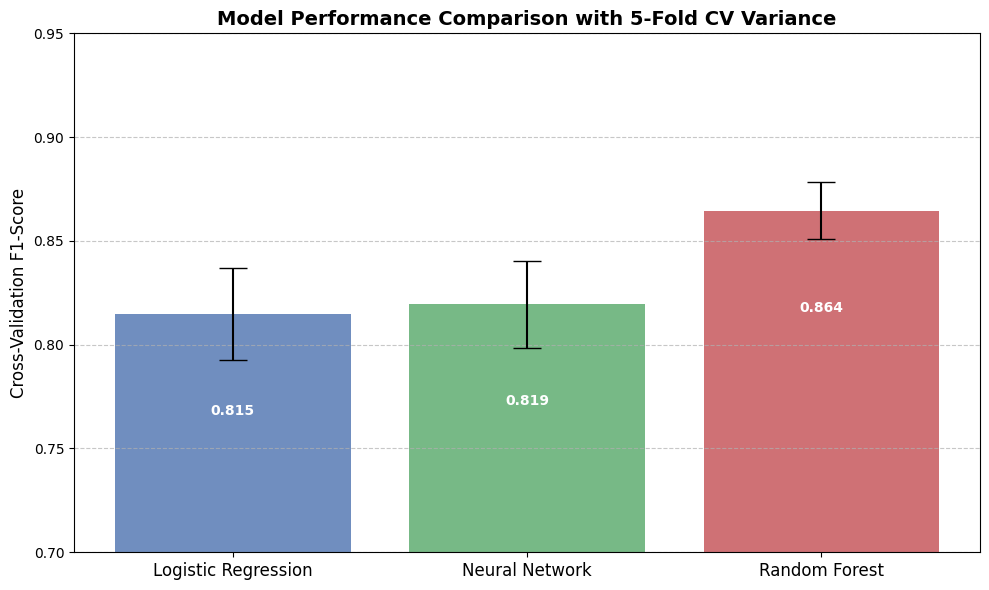

In [20]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Define the models and extract their best mean F1-scores
models = ['Logistic Regression', 'Neural Network', 'Random Forest']
means = [
    grid_search_refined.best_score_,
    grid_search_mlp.best_score_,
    grid_search_rf.best_score_
]

# 2. Extract the standard deviation (variance) for those specific best scores
std_logreg = grid_search_refined.cv_results_['std_test_score'][grid_search_refined.best_index_]
std_mlp = grid_search_mlp.cv_results_['std_test_score'][grid_search_mlp.best_index_]
std_rf = grid_search_rf.cv_results_['std_test_score'][grid_search_rf.best_index_]
stds = [std_logreg, std_mlp, std_rf]

# 3. Plot the bar chart with error bars (yerr)
plt.figure(figsize=(10, 6))
x_pos = np.arange(len(models))
bars = plt.bar(x_pos, means, yerr=stds, align='center', alpha=0.8, ecolor='black', capsize=10, color=['#4C72B0', '#55A868', '#C44E52'])

# 4. Formatting
plt.ylabel('Cross-Validation F1-Score', fontsize=12)
plt.xticks(x_pos, models, fontsize=12)
plt.title('Model Performance Comparison with 5-Fold CV Variance', fontsize=14, fontweight='bold')
plt.ylim(0.7, 0.95) # Zoomed in to clearly show the differences
plt.grid(axis='y', linestyle='--', alpha=0.7)

# 5. Add exact numbers inside the bars
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval - 0.05, f"{yval:.3f}", ha='center', va='bottom', color='white', fontweight='bold')

plt.tight_layout()
plt.show()

## 5.2 Extracts and visualizes the top 10 most important clinical features identified by the optimized Random Forest.

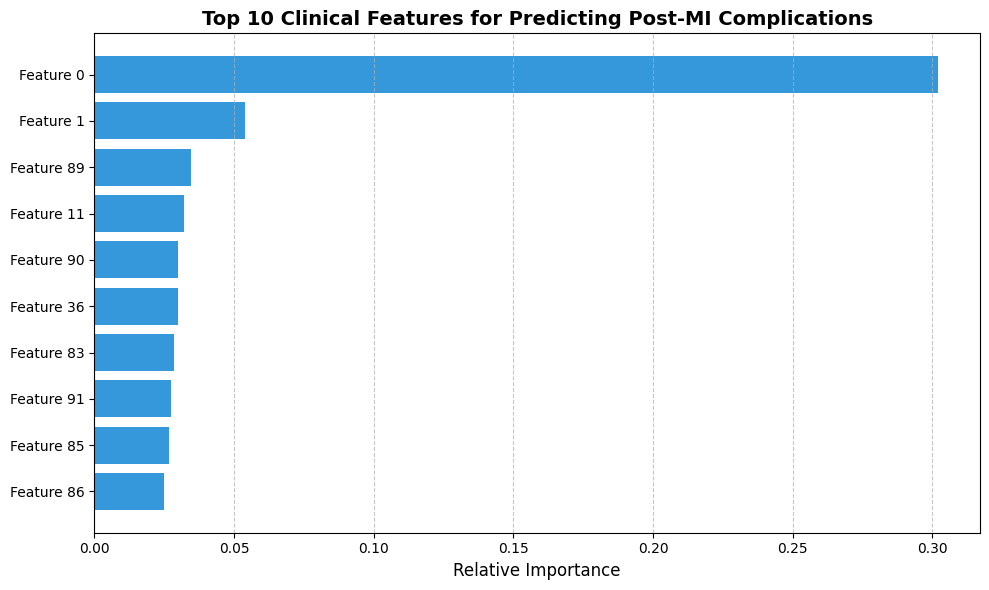

In [21]:
# 1. Extract feature importances from the best Random Forest model
importances = best_rf.feature_importances_
feature_names = X_imputed.columns

# 2. Sort the features by importance in descending order
indices = np.argsort(importances)[::-1]

# 3. Select the top 10 most important features
top_n = 10
top_indices = indices[:top_n]
top_importances = importances[top_indices]
top_features = feature_names[top_indices]

# 4. Plot the horizontal bar chart
plt.figure(figsize=(10, 6))
plt.barh(range(top_n), top_importances, align='center', color='#3498db')
plt.yticks(range(top_n), [f"Feature {feat}" for feat in top_features]) # Naming them generically since we use numbered columns
plt.gca().invert_yaxis()  # Put the highest importance at the top
plt.xlabel('Relative Importance', fontsize=12)
plt.title('Top 10 Clinical Features for Predicting Post-MI Complications', fontsize=14, fontweight='bold')
plt.grid(axis='x', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

## 5.3 Generates a Receiver Operating Characteristic (ROC) curve to compare the Area Under the Curve (AUC) for the optimized models.

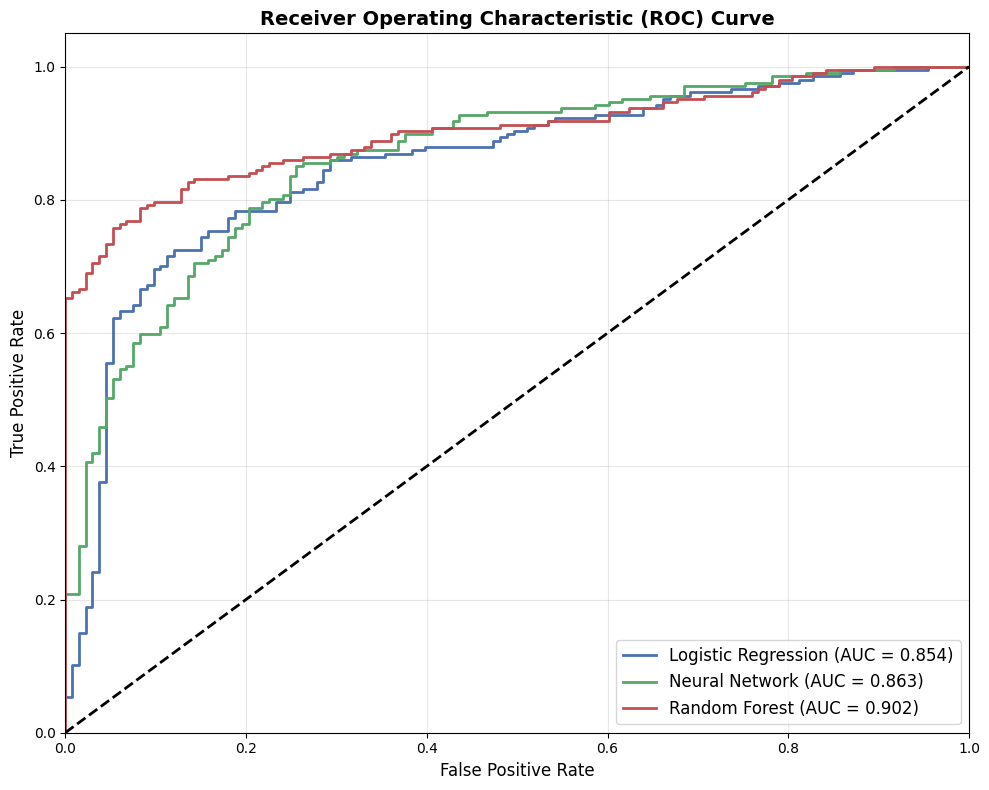

In [22]:
from sklearn.metrics import roc_curve, auc

plt.figure(figsize=(10, 8))

# 1. Predict probabilities for all three models
y_prob_logreg = best_logreg_refined.predict_proba(X_test_scaled)[:, 1]
y_prob_mlp = best_mlp.predict_proba(X_test_scaled)[:, 1]
y_prob_rf = best_rf.predict_proba(X_test_scaled)[:, 1]

# 2. Calculate False Positive Rate (FPR), True Positive Rate (TPR), and AUC
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob_logreg)
roc_auc_lr = auc(fpr_lr, tpr_lr)

fpr_mlp, tpr_mlp, _ = roc_curve(y_test, y_prob_mlp)
roc_auc_mlp = auc(fpr_mlp, tpr_mlp)

fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)
roc_auc_rf = auc(fpr_rf, tpr_rf)

# 3. Plot the curves
plt.plot(fpr_lr, tpr_lr, label=f'Logistic Regression (AUC = {roc_auc_lr:.3f})', linewidth=2, color='#4C72B0')
plt.plot(fpr_mlp, tpr_mlp, label=f'Neural Network (AUC = {roc_auc_mlp:.3f})', linewidth=2, color='#55A868')
plt.plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = {roc_auc_rf:.3f})', linewidth=2, color='#C44E52')

# 4. Plot the random guessing baseline (diagonal line)
plt.plot([0, 1], [0, 1], 'k--', linewidth=2)

# 5. Formatting
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.title('Receiver Operating Characteristic (ROC) Curve', fontsize=14, fontweight='bold')
plt.legend(loc="lower right", fontsize=12)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()